In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\AMIT\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:
import re
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
documents = [
    "football team won the match with excellent goals",
    "the player scored a goal in the football match",
    "cricket team played a great match today",
    "python programming is useful for machine learning",
    "artificial intelligence and machine learning are growing",
    "software developers use python for data science",
    "pizza burger and pasta are popular food items",
    "cooking fresh vegetables makes healthy food",
    "restaurants serve delicious meals and tasty dishes"
]

print("Total documents:", len(documents))

for i, doc in enumerate(documents, start=1):
    print(f"{i}. {doc}")

Total documents: 9
1. football team won the match with excellent goals
2. the player scored a goal in the football match
3. cricket team played a great match today
4. python programming is useful for machine learning
5. artificial intelligence and machine learning are growing
6. software developers use python for data science
7. pizza burger and pasta are popular food items
8. cooking fresh vegetables makes healthy food
9. restaurants serve delicious meals and tasty dishes


In [4]:
vectorizer = CountVectorizer(
    stop_words="english",
    max_df=1.0,
    min_df=1
)

doc_term_matrix = vectorizer.fit_transform(documents)

print("Document-term matrix shape:", doc_term_matrix.shape)
print("Vocabulary:")
print(vectorizer.get_feature_names_out())

Document-term matrix shape: (9, 43)
Vocabulary:
['artificial' 'burger' 'cooking' 'cricket' 'data' 'delicious' 'developers'
 'dishes' 'excellent' 'food' 'football' 'fresh' 'goal' 'goals' 'great'
 'growing' 'healthy' 'intelligence' 'items' 'learning' 'machine' 'makes'
 'match' 'meals' 'pasta' 'pizza' 'played' 'player' 'popular' 'programming'
 'python' 'restaurants' 'science' 'scored' 'serve' 'software' 'tasty'
 'team' 'today' 'use' 'useful' 'vegetables' 'won']


In [5]:
lda_model = LatentDirichletAllocation(
    n_components=3,
    random_state=42,
    max_iter=20,
    learning_method="batch"
)

lda_model.fit(doc_term_matrix)

print("LDA model trained successfully!")
print("Number of topics:", lda_model.n_components)

LDA model trained successfully!
Number of topics: 3


In [6]:
feature_names = vectorizer.get_feature_names_out()

def display_topics(model, feature_names, n_top_words=6):
    for topic_idx, topic in enumerate(model.components_):
        top_indices = topic.argsort()[-n_top_words:][::-1]
        top_words = [feature_names[i] for i in top_indices]

        print(f"Topic {topic_idx + 1}: {', '.join(top_words)}")

display_topics(lda_model, feature_names)

Topic 1: python, machine, learning, restaurants, dishes, delicious
Topic 2: food, healthy, vegetables, makes, fresh, cooking
Topic 3: match, football, team, excellent, goals, won


In [7]:
topic_distributions = lda_model.transform(doc_term_matrix)

for i, distribution in enumerate(topic_distributions):
    dominant_topic = distribution.argmax() + 1

    print(f"\nDocument {i + 1}: {documents[i]}")
    print("Topic probabilities:", distribution.round(3))
    print("Dominant topic:", dominant_topic)


Document 1: football team won the match with excellent goals
Topic probabilities: [0.048 0.049 0.903]
Dominant topic: 3

Document 2: the player scored a goal in the football match
Topic probabilities: [0.056 0.056 0.888]
Dominant topic: 3

Document 3: cricket team played a great match today
Topic probabilities: [0.048 0.895 0.057]
Dominant topic: 2

Document 4: python programming is useful for machine learning
Topic probabilities: [0.065 0.879 0.056]
Dominant topic: 2

Document 5: artificial intelligence and machine learning are growing
Topic probabilities: [0.885 0.059 0.056]
Dominant topic: 1

Document 6: software developers use python for data science
Topic probabilities: [0.903 0.049 0.048]
Dominant topic: 1

Document 7: pizza burger and pasta are popular food items
Topic probabilities: [0.048 0.904 0.048]
Dominant topic: 2

Document 8: cooking fresh vegetables makes healthy food
Topic probabilities: [0.048 0.904 0.048]
Dominant topic: 2

Document 9: restaurants serve delicious me

In [8]:
import pandas as pd

topic_columns = [
    f"Topic {i + 1}"
    for i in range(lda_model.n_components)
]

topic_df = pd.DataFrame(
    topic_distributions,
    columns=topic_columns
)

topic_df.insert(0, "Document", documents)

topic_df.round(3)

,Document,Topic 1,Topic 2,Topic 3
0,football team won the match with excellent goals,0.048,0.049,0.903
1,the player scored a goal in the football match,0.056,0.056,0.888
2,cricket team played a great match today,0.048,0.895,0.057
3,python programming is useful for machine learning,0.065,0.879,0.056
4,artificial intelligence and machine learning a...,0.885,0.059,0.056
5,software developers use python for data science,0.903,0.049,0.048
6,pizza burger and pasta are popular food items,0.048,0.904,0.048
7,cooking fresh vegetables makes healthy food,0.048,0.904,0.048
8,restaurants serve delicious meals and tasty di...,0.904,0.048,0.048


In [9]:
new_document = [
    "python machine learning helps software developers"
]

new_vector = vectorizer.transform(new_document)

if new_vector.nnz == 0:
    print("No known vocabulary words found in the new document.")
else:
    new_topic_probs = lda_model.transform(new_vector)[0]
    dominant_topic = new_topic_probs.argmax() + 1

    print("New document:", new_document[0])
    print("Topic probabilities:", new_topic_probs.round(3))
    print("Dominant topic:", dominant_topic)

New document: python machine learning helps software developers
Topic probabilities: [0.883 0.061 0.056]
Dominant topic: 1


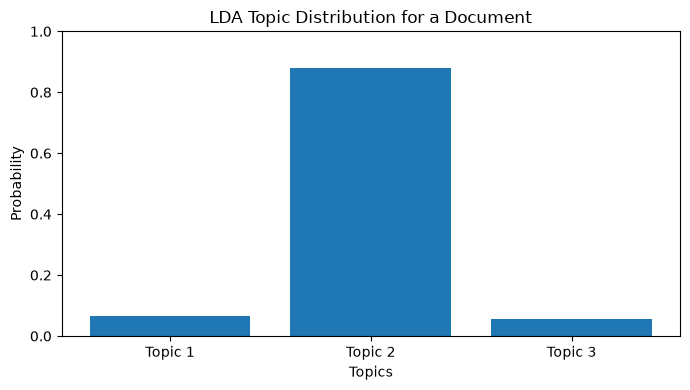

In [10]:
import matplotlib.pyplot as plt

document_index = 3  # Fourth document

plt.figure(figsize=(7, 4))
plt.bar(
    topic_columns,
    topic_distributions[document_index]
)

plt.title("LDA Topic Distribution for a Document")
plt.xlabel("Topics")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()